In [1]:
!pip install -q ultralytics roboflow gradio

In [2]:
from roboflow import Roboflow
import os, shutil, glob, random, yaml
from ultralytics import YOLO

API_KEY = "XXXXXXXXXXXXXXX"
rf = Roboflow(api_key=API_KEY)

ds_pneu = rf.workspace("car-parts-straight-photos").project("tire-flat").version(1).download("yolov8")
ds_vidro = rf.workspace("project-kmnth").project("broken-car-window").version(1).download("yolov8")
ds_colisao = rf.workspace("mada-study").project("crash-car-detection").version(4).download("yolov8")

fontes = [
    {"dir": ds_pneu.location, "id": 0},
    {"dir": ds_vidro.location, "id": 1},
    {"dir": ds_colisao.location, "id": 2},
]

destino = "/content/dataset_limpo_v3"
if os.path.exists(destino):
    shutil.rmtree(destino)

for split in ["train", "valid", "test"]:
    os.makedirs(f"{destino}/{split}/images", exist_ok=True)
    os.makedirs(f"{destino}/{split}/labels", exist_ok=True)

todas_imagens = {0: [], 1: [], 2: []}
for f_info in fontes:
    for sub in ["train", "valid", "val", "test"]:
        for img_path in glob.glob(f"{f_info['dir']}/{sub}/images/*"):
            base = os.path.splitext(os.path.basename(img_path))[0]
            lbl_path = f"{f_info['dir']}/{sub}/labels/{base}.txt"
            if os.path.exists(lbl_path):
                todas_imagens[f_info["id"]].append((img_path, lbl_path))

random.seed(42)
for cls_id, pares in todas_imagens.items():
    random.shuffle(pares)
    pares = pares[:300]
    n = len(pares)
    n_val, n_test = max(1, int(n * 0.20)), max(1, int(n * 0.10))
    divisoes = {
        "valid": pares[:n_val],
        "test": pares[n_val:n_val + n_test],
        "train": pares[n_val + n_test:]
    }

    for split, lista in divisoes.items():
        for idx, (img_p, lbl_p) in enumerate(lista):
            ext = os.path.splitext(img_p)[1]
            shutil.copy(img_p, f"{destino}/{split}/images/c{cls_id}_{idx}{ext}")
            with open(lbl_p) as f:
                novas = [f"{cls_id} " + " ".join(l.split()[1:]) + "\n" for l in f if len(l.split()) >= 5]
            with open(f"{destino}/{split}/labels/c{cls_id}_{idx}.txt", "w") as f:
                f.writelines(novas)

with open(f"{destino}/data.yaml", "w") as f:
    yaml.dump({
        "train": f"{destino}/train/images",
        "val": f"{destino}/valid/images",
        "test": f"{destino}/test/images",
        "nc": 3,
        "names": ["pneu_furado", "vidro_quebrado", "colisao_lataria"]
    }, f)

for split in ["train", "valid", "test"]:
    c = [len(glob.glob(f"{destino}/{split}/images/c{i}_*")) for i in range(3)]
    print(f"{split.upper()}: pneu_furado={c[0]} | vidro_quebrado={c[1]} | colisao_lataria={c[2]}")

model = YOLO("yolov8m.pt")
results = model.train(
    data=f"{destino}/data.yaml",
    epochs=70,
    imgsz=640,
    batch=16,
    cos_lr=True,
    erasing=0.0,
    patience=15,
    name="guincho_vision_m_v3"
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to tire-flat-1 in yolov8:: 100%|██████████| 1376/1376 [00:00<00:00, 8553.93it/s]

loading Roboflow workspace...


loading Roboflow project...



Extracting Dataset Version Zip to Broken-car-window-1 in yolov8:: 100%|██████████| 2110/2110 [00:00<00:00, 3440.14it/s]


loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Crash-Car-Detection-4 in yolov8:: 100%|██████████| 5110/5110 [00:00<00:00, 6523.23it/s]


TRAIN: pneu_furado=210 | vidro_quebrado=210 | colisao_lataria=210
VALID: pneu_furado=60 | vidro_quebrado=60 | colisao_lataria=60
TEST: pneu_furado=30 | vidro_quebrado=30 | colisao_lataria=30
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/dataset_limpo_v3/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=70, erasing=0.0, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, l

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 92 layers, 25,841,497 parameters, 0 gradients, 78.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1165.2±555.9 MB/s, size: 42.7 KB)
val: Scanning /content/dataset_limpo_v3/valid/labels.cache... 180 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 180/180 44.4Mit/s 0.0s
WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 13, len(boxes) = 196. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 12/12 2.2it/s 5.6s
                   all        180        196       0.86      0.767      0.803      0.597
           pneu_furado         60         60      0.965          1      0.995      0.934
        vidro_quebrado         60

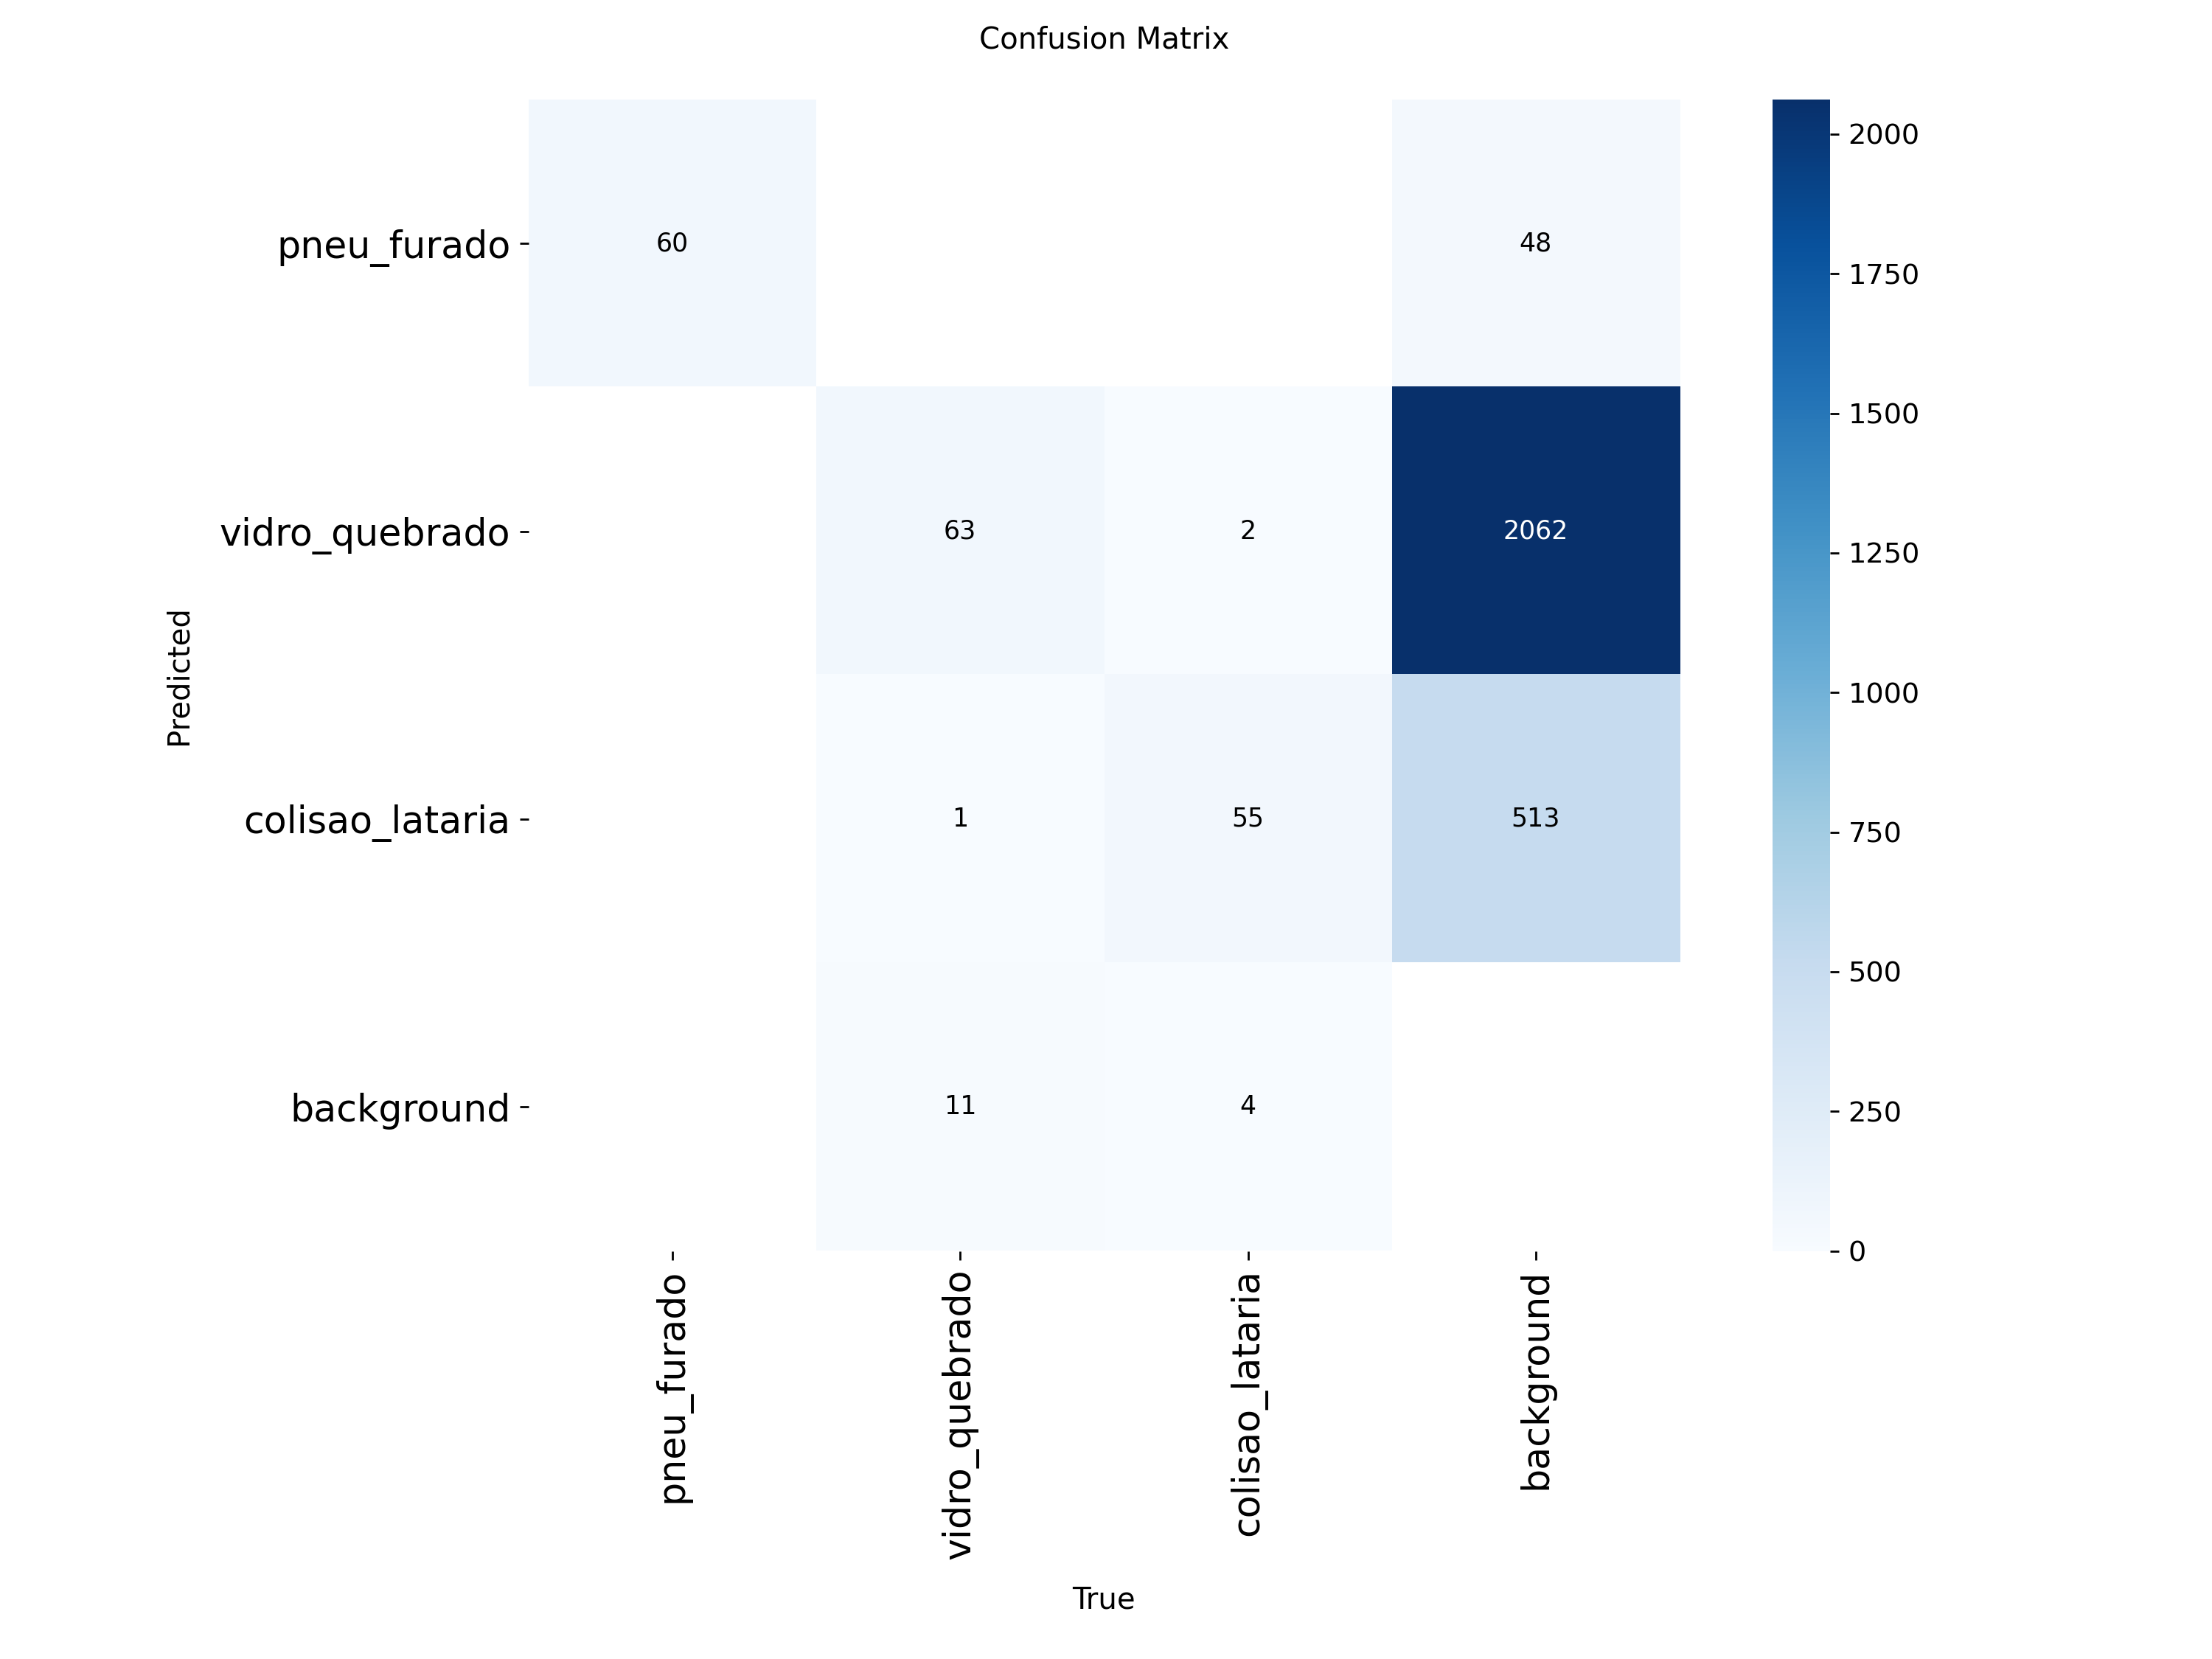

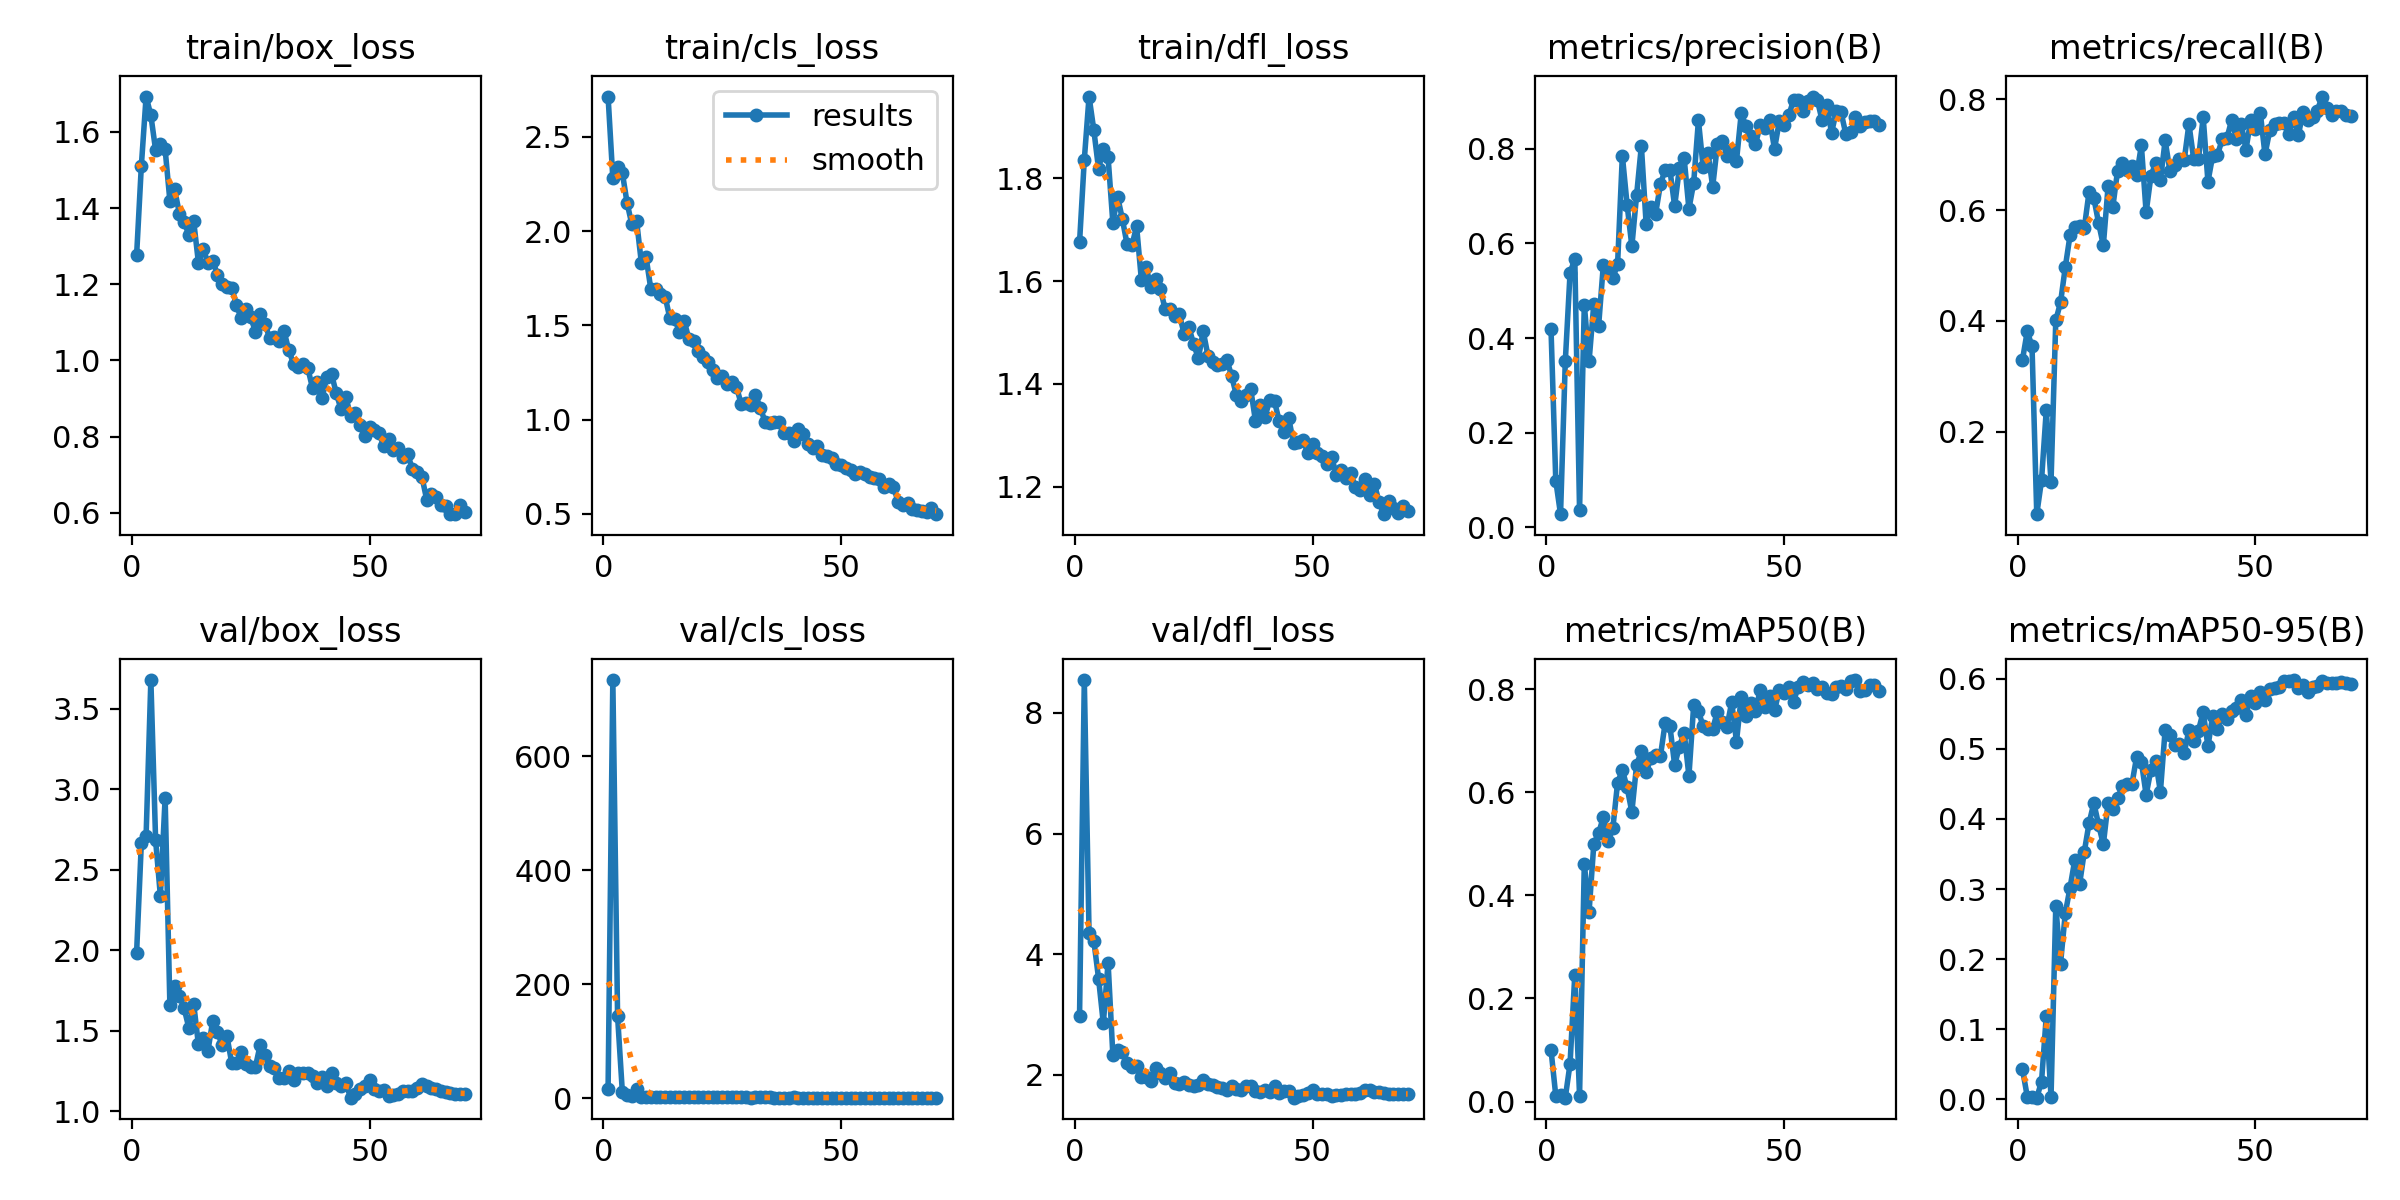

In [3]:
from ultralytics import YOLO
from IPython.display import Image, display

best_model = YOLO("/content/runs/detect/guincho_vision_m_v3/weights/best.pt")
metrics = best_model.val(data="/content/dataset_limpo_v3/data.yaml")

print(f"Precision Geral: {metrics.box.mp:.3f}")
print(f"Recall Geral: {metrics.box.mr:.3f}")
print(f"mAP50 Geral: {metrics.box.map50:.3f}")

display(Image(filename="/content/runs/detect/guincho_vision_m_v3/confusion_matrix.png", width=650))
display(Image(filename="/content/runs/detect/guincho_vision_m_v3/results.png", width=750))

In [5]:
import gradio as gr
import cv2
import time
from ultralytics import YOLO

model = YOLO("/content/runs/detect/guincho_vision_m_v3/weights/best.pt")

REGRAS_TRIAGEM = {
    "pneu_furado": {
        "titulo": "Pneu Furado ou Rasgado",
        "modal": "Borracheiro Móvel / Troca de Estepe",
        "adicional": 85.00,
        "eta": "14 min",
        "gravidade": "Moderada",
        "cor_badge": "#b45309",
        "bg_badge": "#fef3c7",
        "instrucao": "Mantenha o veículo estacionado em local plano com o pisca-alerta acionado. Atendimento realizado no local."
    },
    "vidro_quebrado": {
        "titulo": "Vidro ou Para-brisa Danificado",
        "modal": "Guincho Plataforma com Vedação",
        "adicional": 180.00,
        "eta": "22 min",
        "gravidade": "Alta",
        "cor_badge": "#c2410c",
        "bg_badge": "#ffedd5",
        "instrucao": "Evite trafegar para impedir o espalhamento de estilhaços. Embarque com película de proteção climática."
    },
    "colisao_lataria": {
        "titulo": "Colisão / Avaria Estrutural",
        "modal": "Guincho Plataforma Hidráulica",
        "adicional": 240.00,
        "eta": "26 min",
        "gravidade": "Crítica",
        "cor_badge": "#b91c1c",
        "bg_badge": "#fee2e2",
        "instrucao": "Posicione o triângulo de sinalização a 30 metros do veículo e aguarde fora da pista de rolamento."
    },
}

DESTINOS_ROTA = {
    "Oficina Credenciada Mais Próxima (6,4 km)": 6.4,
    "Concessionária Autorizada - Av. Ibirapuera (11,2 km)": 11.2,
    "Residência do Segurado - Zona Sul (15,8 km)": 15.8,
    "Base Operacional / Pátio Central (22,0 km)": 22.0,
}

CSS_CUSTOM = """
@import url('https://fonts.googleapis.com/css2?family=Inter:wght@400;500;600;700&display=swap');

html, body {
    margin: 0 !important;
    padding: 0 !important;
    overflow-x: hidden !important;
    font-family: 'Inter', -apple-system, BlinkMacSystemFont, sans-serif !important;
    background-color: #f8fafc !important;
}

.gradio-container {
    max-width: 1360px !important;
    margin: 0 auto !important;
    padding: 12px 20px !important;
    min-height: 100vh !important;
    box-sizing: border-box !important;
}

footer { display: none !important; }

.app-header {
    background: #ffffff;
    border: 1px solid #e2e8f0;
    border-radius: 10px;
    padding: 12px 20px;
    margin-bottom: 10px;
    display: flex;
    justify-content: space-between;
    align-items: center;
}

.app-title {
    font-size: 17px;
    font-weight: 700;
    color: #0f172a;
    margin: 0;
    letter-spacing: -0.02em;
}

.app-subtitle {
    font-size: 12px;
    color: #64748b;
    margin: 2px 0 0 0;
}

.status-pill {
    font-size: 11px;
    font-weight: 600;
    color: #0f172a;
    background: #f1f5f9;
    border: 1px solid #cbd5e1;
    padding: 5px 10px;
    border-radius: 6px;
}

.panel-card {
    background: #ffffff !important;
    border: 1px solid #e2e8f0 !important;
    border-radius: 10px !important;
    padding: 12px !important;
    box-shadow: 0 1px 2px rgba(15, 23, 42, 0.03) !important;
}

.btn-primary-custom {
    background: #0f172a !important;
    color: #ffffff !important;
    border: none !important;
    font-weight: 600 !important;
    font-size: 13px !important;
    border-radius: 8px !important;
    padding: 10px 14px !important;
    margin-top: 4px !important;
}

.btn-primary-custom:hover {
    background: #1e293b !important;
}
"""

def diagnosticar_e_cotar(imagem, origem, destino_selecionado, placa):
    if imagem is None:
        return None, """
        <div style="background:#ffffff;border:1px solid #e2e8f0;border-radius:10px;padding:24px 20px;text-align:center;color:#64748b;margin-top:8px;">
            <div style="font-size:13px;font-weight:600;color:#0f172a;margin-bottom:4px;">Aguardando captura ou envio da imagem</div>
            <div style="font-size:12px;">Insira o registro fotográfico do veículo para executar a triagem visual e calcular o valor fixo.</div>
        </div>
        """

    t0 = time.perf_counter()
    results = model.predict(imagem, conf=0.18, iou=0.45, verbose=False)
    inferencia_ms = (time.perf_counter() - t0) * 1000

    img_anotada_rgb = cv2.cvtColor(results[0].plot(), cv2.COLOR_BGR2RGB)

    img_anotada_bgr = results[0].plot()
    img_anotada_rgb = cv2.cvtColor(img_anotada_bgr, cv2.COLOR_BGR2RGB)

    distancia_km = DESTINOS_ROTA.get(destino_selecionado, 8.5)
    taxa_deslocamento = 90.00 + (distancia_km * 4.50)

    adicional_avaria = 0.00
    modal_final = "Guincho Plataforma Padrão"
    eta_final = "18 min"
    gravidade_final = "Baixa"
    cor_badge = "#047857"
    bg_badge = "#d1fae5"
    instrucao_final = "Nenhuma avaria estrutural crítica identificada. Reboque padrão selecionado para remoção."

    prioridade = {"colisao_lataria": 3, "vidro_quebrado": 2, "pneu_furado": 1}
    deteccoes = []

    for box in results[0].boxes:
        cls_id = int(box.cls[0])
        classe = model.names[cls_id]
        conf = round(float(box.conf[0]) * 100, 1)
        deteccoes.append((prioridade.get(classe, 0), classe, conf))

    deteccoes.sort(reverse=True)

    linhas_deteccao = ""
    if deteccoes:
        _, classe_principal, _ = deteccoes[0]
        regra_principal = REGRAS_TRIAGEM[classe_principal]
        modal_final = regra_principal["modal"]
        eta_final = regra_principal["eta"]
        gravidade_final = regra_principal["gravidade"]
        cor_badge = regra_principal["cor_badge"]
        bg_badge = regra_principal["bg_badge"]
        instrucao_final = regra_principal["instrucao"]

        if classe_principal == "pneu_furado" and len(deteccoes) == 1:
            taxa_deslocamento = 65.00
            rota_texto = "Atendimento no local (sem reboque)"
        else:
            rota_texto = f"Rota calculada: {distancia_km:.1f} km"

        for _, cls_nome, conf_val in deteccoes:
            r = REGRAS_TRIAGEM[cls_nome]
            adicional_avaria += r["adicional"]
            linhas_deteccao += f"""
            <div style="display:flex;justify-content:space-between;align-items:center;padding:6px 10px;background:#f8fafc;border:1px solid #e2e8f0;border-radius:6px;margin-bottom:4px;">
                <span style="font-size:12px;font-weight:500;color:#0f172a;">{r['titulo']}</span>
                <span style="font-size:11px;font-weight:600;color:#475569;background:#e2e8f0;padding:2px 6px;border-radius:4px;">Confiança: {conf_val}%</span>
            </div>
            """
    else:
        rota_texto = f"Rota calculada: {distancia_km:.1f} km"
        linhas_deteccao = """
        <div style="padding:8px 10px;background:#f8fafc;border:1px solid #e2e8f0;border-radius:6px;font-size:12px;color:#475569;">
            Nenhuma avaria externa detectada (atendimento para pane elétrica ou mecânica).
        </div>
        """

    preco_fixo = taxa_deslocamento + adicional_avaria
    placa_formatada = placa.strip().upper() if placa.strip() else "NÃO INFORMADA"

    card_html = f"""
    <div style="background:#ffffff;border:1px solid #e2e8f0;border-radius:10px;padding:14px 16px;margin-top:8px;box-shadow:0 1px 2px rgba(15,23,42,0.03);">
        <div style="display:flex;justify-content:space-between;align-items:center;padding-bottom:10px;border-bottom:1px solid #e2e8f0;margin-bottom:10px;">
            <div>
                <div style="font-size:13px;font-weight:700;color:#0f172a;">Veículo {placa_formatada} <span style="font-weight:400;color:#64748b;">&bull; {rota_texto}</span></div>
                <div style="font-size:11px;color:#64748b;margin-top:1px;">Origem: {origem}</div>
            </div>
            <div style="text-align:right;">
                <span style="background:{bg_badge};color:{cor_badge};font-size:11px;font-weight:600;padding:3px 8px;border-radius:5px;">
                    Severidade: {gravidade_final}
                </span>
                <div style="font-size:10px;color:#94a3b8;margin-top:3px;">Inferência: {inferencia_ms:.1f} ms</div>
            </div>
        </div>

        <div style="margin-bottom:10px;">
            <div style="font-size:10px;font-weight:600;color:#64748b;text-transform:uppercase;letter-spacing:0.05em;margin-bottom:5px;">
                Diagnóstico Visual Automatizado
            </div>
            {linhas_deteccao}
        </div>

        <div style="display:grid;grid-template-columns:1fr 1fr;gap:8px;margin-bottom:10px;">
            <div style="background:#f8fafc;border:1px solid #e2e8f0;padding:8px 10px;border-radius:6px;">
                <div style="font-size:10px;font-weight:600;color:#64748b;text-transform:uppercase;">Modal Alocado</div>
                <div style="font-size:12px;font-weight:600;color:#0f172a;margin-top:2px;">{modal_final}</div>
            </div>
            <div style="background:#f8fafc;border:1px solid #e2e8f0;padding:8px 10px;border-radius:6px;">
                <div style="font-size:10px;font-weight:600;color:#64748b;text-transform:uppercase;">Previsão de Chegada</div>
                <div style="font-size:12px;font-weight:600;color:#0f172a;margin-top:2px;">{eta_final} (Socorrista a 3,2 km)</div>
            </div>
        </div>

        <div style="background:#f8fafc;border-left:3px solid #0f172a;padding:7px 10px;border-radius:0 6px 6px 0;margin-bottom:12px;">
            <div style="font-size:11px;color:#334155;line-height:1.35;"><strong>Protocolo:</strong> {instrucao_final}</div>
        </div>

        <div style="display:flex;justify-content:space-between;align-items:center;background:#0f172a;color:#ffffff;padding:12px 16px;border-radius:8px;">
            <div>
                <div style="font-size:10px;font-weight:500;color:#94a3b8;text-transform:uppercase;letter-spacing:0.05em;">Valor Fixo Garantido (Pay-per-Use)</div>
                <div style="font-size:11px;color:#cbd5e1;margin-top:1px;">Base R$ {taxa_deslocamento:.2f} + Operação R$ {adicional_avaria:.2f}</div>
            </div>
            <div style="font-size:22px;font-weight:700;letter-spacing:-0.02em;color:#ffffff;">
                R$ {preco_fixo:.2f}
            </div>
        </div>
    </div>
    """
    return img_anotada_rgb, card_html

tema = gr.themes.Default(
    primary_hue="slate",
    neutral_hue="slate",
    font=[gr.themes.GoogleFont("Inter"), "sans-serif"]
)

with gr.Blocks(theme=tema, css=CSS_CUSTOM, title="ResgateJá | Triagem Assistida") as demo:
    gr.HTML("""
    <div class="app-header">
        <div>
            <h1 class="app-title">ResgateJá &mdash; Assistência Veicular Sob Demanda</h1>
            <p class="app-subtitle">Módulo de Triagem Visual e Precificação Dinâmica &bull; Arquitetura YOLOv8m</p>
        </div>
        <div class="status-pill">Modelo Ativo &bull; mAP@50 81.5%</div>
    </div>
    """)

    with gr.Row(equal_height=False):
        with gr.Column(scale=5, elem_classes=["panel-card"]):
            img_input = gr.Image(
                label="Registro Fotográfico da Avaria",
                sources=["upload", "webcam"],
                type="numpy",
                height=230
            )
            with gr.Row():
                placa_input = gr.Textbox(label="Placa", value="ABC-1D23", scale=1)
                origem_input = gr.Textbox(label="Localização Atual (GPS)", value="Av. Paulista, 1106 - São Paulo", scale=2)
            destino_input = gr.Dropdown(
                choices=list(DESTINOS_ROTA.keys()),
                value="Oficina Credenciada Mais Próxima (6,4 km)",
                label="Destino do Atendimento (Cálculo Automático de Rota)"
            )
            btn_analisar = gr.Button("Processar Triagem e Calcular Valor", elem_classes=["btn-primary-custom"])

        with gr.Column(scale=6):
            with gr.Group(elem_classes=["panel-card"]):
                img_output = gr.Image(label="Detecção de Avarias (Bounding Boxes)", height=215)
            html_output = gr.HTML(value="""
            <div style="background:#ffffff;border:1px solid #e2e8f0;border-radius:10px;padding:24px 20px;text-align:center;color:#64748b;margin-top:8px;">
                <div style="font-size:13px;font-weight:600;color:#0f172a;margin-bottom:4px;">Aguardando captura ou envio da imagem</div>
                <div style="font-size:12px;">Insira o registro fotográfico do veículo para executar a triagem visual e calcular o valor fixo.</div>
            </div>
            """)

    btn_analisar.click(
        fn=diagnosticar_e_cotar,
        inputs=[img_input, origem_input, destino_input, placa_input],
        outputs=[img_output, html_output]
    )

demo.launch(share=True, debug=False)

The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://83d4239627b217caee.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
